<a href="https://colab.research.google.com/github/stjsmith8/ADS_599_Capstone_Project/blob/main/ADS599_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "/content/drive/MyDrive/Cell_Painting_Capstone/FMP.csv"

df = pd.read_csv(file_path)

In [4]:
print("Dataset dimensions:", df.shape)

display(df.head())

Dataset dimensions: (10697, 2984)


,Metadata_EOS,Metadata_Object_Count,Metadata_Plate,Metadata_Well,Metadata_Partner,Metadata_Batch,Metadata_Concentration,Nuc_AreaShape_Area,Nuc_AreaShape_BoundingBoxArea,Nuc_AreaShape_BoundingBoxMaximum_X,...,Cyto_Texture_Variance_Mito_10_02_256,Cyto_Texture_Variance_Mito_10_03_256,Cyto_Texture_Variance_Mito_3_00_256,Cyto_Texture_Variance_Mito_3_01_256,Cyto_Texture_Variance_Mito_3_02_256,Cyto_Texture_Variance_Mito_3_03_256,Cyto_Texture_Variance_Mito_5_00_256,Cyto_Texture_Variance_Mito_5_01_256,Cyto_Texture_Variance_Mito_5_02_256,Cyto_Texture_Variance_Mito_5_03_256
0,EOS100001,700,B1001,A01,Bioactives,R1,10,3.661521,4.796379,-0.701115,...,-3.977178,-5.096992,-4.233304,-4.254603,-4.278443,-4.394287,-4.389678,-4.303942,-4.472754,-4.324122
1,EOS100002,1004,B1001,C01,Bioactives,R1,10,-0.578135,-0.074943,-0.177498,...,-1.093549,-1.359570,-1.152115,-1.189020,-1.094189,-1.218019,-1.239355,-1.250434,-1.183482,-1.230184
2,EOS100003,516,B1001,E01,Bioactives,R1,10,9.924650,16.749854,-0.434869,...,0.971550,1.826429,1.221991,1.077488,1.226752,1.213625,1.168021,1.058912,1.094057,1.043186
3,EOS100004,792,B1001,G01,Bioactives,R1,10,1.445337,4.121888,-1.127110,...,-0.819019,-0.970849,-0.810992,-0.876542,-0.802648,-0.874929,-0.872137,-0.966977,-0.860790,-0.942076
4,EOS100005,857,B1001,I01,Bioactives,R1,10,-1.284744,-2.173359,-1.064985,...,-3.086765,-3.889653,-3.258110,-3.252077,-3.294311,-3.360850,-3.366353,-3.355708,-3.502674,-3.400231


In [5]:
# Identify metadata columns
metadata_cols = [col for col in df.columns
                 if col.startswith("Metadata_")]

print("Metadata columns:")
print(metadata_cols)

print("\nUnique experimental batches:")
print(df["Metadata_Batch"].value_counts(dropna=False))

print("\nUnique plates:")
print(df["Metadata_Plate"].nunique())

print("\nUnique compounds:")
print(df["Metadata_EOS"].nunique())

Metadata columns:
['Metadata_EOS', 'Metadata_Object_Count', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Partner', 'Metadata_Batch', 'Metadata_Concentration']

Unique experimental batches:
Metadata_Batch
R3    2677
R2    2674
R4    2674
R1    2672
Name: count, dtype: int64

Unique plates:
7

Unique compounds:
2462


In [6]:
# Count unique batches for each compound
compound_batches = (
    df.groupby("Metadata_EOS")["Metadata_Batch"]
    .nunique()
)

# Display the number of compounds with 1, 2, 3, or 4 batches
print("Number of batches per compound:")
print(compound_batches.value_counts().sort_index())

# Count compounds with all four batches
complete_compounds = (compound_batches == 4).sum()

print("\nCompounds with all four batches:", complete_compounds)

Number of batches per compound:
Metadata_Batch
1       4
2       5
3      13
4    2440
Name: count, dtype: int64

Compounds with all four batches: 2440


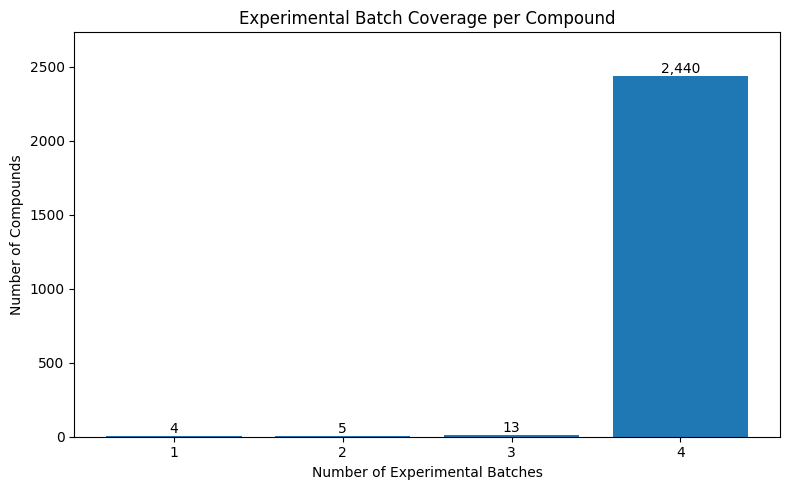

In [7]:
batch_counts = compound_batches.value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    batch_counts.index.astype(str),
    batch_counts.values
)

plt.title("Experimental Batch Coverage per Compound")
plt.xlabel("Number of Experimental Batches")
plt.ylabel("Number of Compounds")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.ylim(0, batch_counts.max() * 1.12)
plt.tight_layout()
plt.show()


In [8]:
# Count observations for each compound within each batch
compound_batch_counts = (
    df.groupby(["Metadata_EOS", "Metadata_Batch"])
    .size()
)

# Show how many compound-batch combinations have
# 1, 2, 3, or more observations
print("Observations per compound per batch:")
print(compound_batch_counts.value_counts().sort_index())

# Identify combinations with multiple observations
duplicates = compound_batch_counts[
    compound_batch_counts > 1
]

print("\nCompound-batch combinations with multiple observations:")
print(len(duplicates))

display(duplicates.head(10))

Observations per compound per batch:
1      9801
14        8
196       4
Name: count, dtype: int64

Compound-batch combinations with multiple observations:
12


Metadata_EOS  Metadata_Batch
DMSO          R1                196
              R2                196
              R3                196
              R4                196
Nocodazole    R1                 14
              R2                 14
              R3                 14
              R4                 14
Tetrandrine   R1                 14
              R2                 14
dtype: int64

In [9]:
# Display every compound-batch combination
# that has more than one observation

display(duplicates.reset_index(name="Observation_Count"))

# Examine repeated compounds and their experimental conditions

repeated_compounds = duplicates.index.get_level_values(
    "Metadata_EOS"
).unique()

summary = (
    df[df["Metadata_EOS"].isin(repeated_compounds)]
    .groupby(["Metadata_EOS", "Metadata_Batch"])
    .agg(
        observations=("Metadata_Well", "size"),
        unique_wells=("Metadata_Well", "nunique"),
        unique_concentrations=("Metadata_Concentration", "nunique")
    )
)

display(summary)

,Metadata_EOS,Metadata_Batch,Observation_Count
0,DMSO,R1,196
1,DMSO,R2,196
2,DMSO,R3,196
3,DMSO,R4,196
4,Nocodazole,R1,14
5,Nocodazole,R2,14
6,Nocodazole,R3,14
7,Nocodazole,R4,14
8,Tetrandrine,R1,14
9,Tetrandrine,R2,14


observations  unique_wells  unique_concentrations
Metadata_EOS Metadata_Batch                                                   
DMSO         R1                       196            28                      1
             R2                       196            28                      1
             R3                       196            28                      1
             R4                       196            28                      1
Nocodazole   R1                        14             2                      1
             R2                        14             2                      1
             R3                        14             2                      1
             R4                        14             2                      1
Tetrandrine  R1                        14             2                      1
             R2                        14             2                      1
             R3                        14             2                      1
             R4                        14             2                      1

In [10]:
# Count observations for each compound, batch, and plate
plate_summary = (
    df[df["Metadata_EOS"].isin(
        ["DMSO", "Nocodazole", "Tetrandrine"]
    )]
    .groupby([
        "Metadata_EOS",
        "Metadata_Batch",
        "Metadata_Plate"
    ])
    .size()
    .reset_index(name="Observation_Count")
)

display(plate_summary.head(25))

,Metadata_EOS,Metadata_Batch,Metadata_Plate,Observation_Count
0,DMSO,R1,B1001,28
1,DMSO,R1,B1002,28
2,DMSO,R1,B1003,28
3,DMSO,R1,B1004,28
4,DMSO,R1,B1005,28
5,DMSO,R1,B1006,28
6,DMSO,R1,B1007,28
7,DMSO,R2,B1001,28
8,DMSO,R2,B1002,28
9,DMSO,R2,B1003,28


In [11]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Keep only columns containing missing values
missing_columns = missing_values[missing_values > 0]

# Summarize missing data
print("Total missing values:", missing_values.sum())

print("Columns with missing values:", len(missing_columns))

print("Percentage of missing cells:",
      round(df.isnull().mean().mean() * 100, 2), "%")

# Display the 10 columns with the most missing values
print("\nTop 10 columns with missing values:")
display(missing_columns.sort_values(ascending=False).head(10))

Total missing values: 0
Columns with missing values: 0
Percentage of missing cells: 0.0 %

Top 10 columns with missing values:


,0


In [12]:
# Select morphological features only
feature_cols = [
    col for col in df.columns
    if not col.startswith("Metadata_")
]

print("Total morphological features:", len(feature_cols))

# Count unique values for each morphological feature
unique_counts = df[feature_cols].nunique()

# Identify features with only one unique value
constant_features = unique_counts[unique_counts <= 1]

print("Number of constant features:", len(constant_features))

print("Percentage of constant features:",
      round(len(constant_features) / len(feature_cols) * 100, 2), "%")

# Display any constant features
display(constant_features.head(10))

Total morphological features: 2977
Number of constant features: 82
Percentage of constant features: 2.75 %


,0
Nuc_AreaShape_EulerNumber,1
Nuc_Correlation_Costes_AGP_ER,1
Nuc_Correlation_Costes_ER_AGP,1
Nuc_Correlation_Costes_ER_DNA,1
Nuc_Correlation_Costes_Mito_AGP,1
Nuc_Correlation_Costes_Mito_ER,1
Cells_AreaShape_EulerNumber,1
Cells_Correlation_Costes_AGP_ER,1
Cells_Correlation_Costes_ER_AGP,1
Cells_RadialDistribution_FracAtD_mito_tubeness_Overflow,1


Cell count summary:


,Metadata_Object_Count
count,10697.000000
mean,819.372067
std,257.337755
min,1.000000
25%,646.000000
50%,863.000000
75%,1014.000000
max,1495.000000


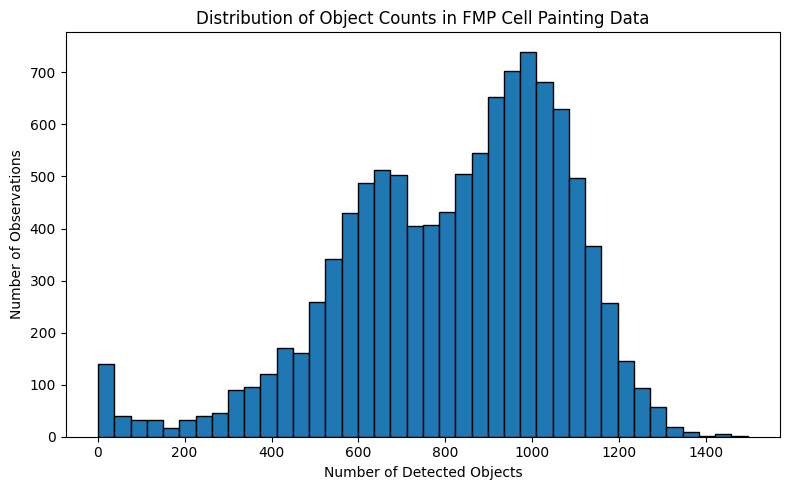

In [13]:
# Summary statistics for cell counts
print("Cell count summary:")
display(df["Metadata_Object_Count"].describe())

# Visualize the distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df["Metadata_Object_Count"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Object Counts in FMP Cell Painting Data")
plt.xlabel("Number of Detected Objects")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [14]:
# Count observations below several exploratory thresholds
for threshold in [50, 100, 200]:
    count = (df["Metadata_Object_Count"] < threshold).sum()
    percentage = count / len(df) * 100

    print(f"Below {threshold} objects: {count} ({percentage:.2f}%)")

# Examine object counts by experimental batch
batch_object_summary = (
    df.groupby("Metadata_Batch")["Metadata_Object_Count"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(batch_object_summary)

Below 50 objects: 155 (1.45%)
Below 100 objects: 200 (1.87%)
Below 200 objects: 270 (2.52%)


,count,mean,median,min,max
Metadata_Batch,,,,,
R1,2672,905.817740,941.5,1,1427
R2,2674,585.396784,616.0,1,963
R3,2677,876.499813,923.0,1,1457
R4,2674,909.774495,965.5,1,1495


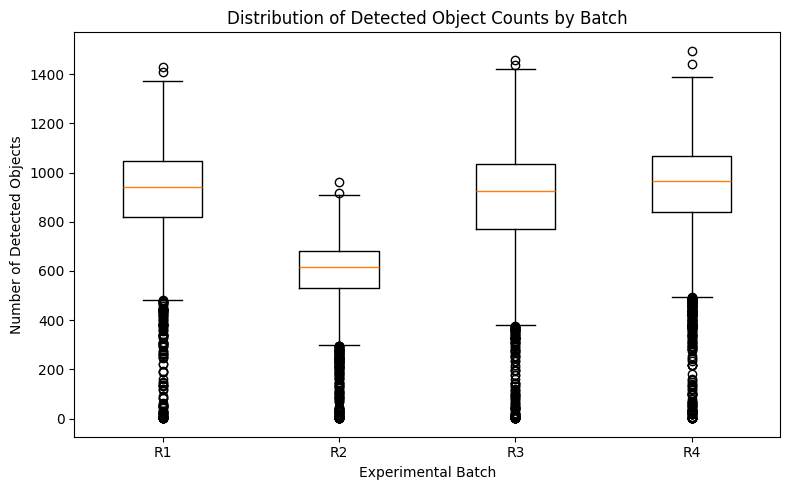

In [15]:
# Compare object count distributions across batches
batch_order = ["R1", "R2", "R3", "R4"]

batch_data = [
    df.loc[
        df["Metadata_Batch"] == batch,
        "Metadata_Object_Count"
    ]
    for batch in batch_order
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    batch_data,
    tick_labels=batch_order,
    showfliers=True
)

plt.title("Distribution of Detected Object Counts by Batch")
plt.xlabel("Experimental Batch")
plt.ylabel("Number of Detected Objects")

plt.tight_layout()
plt.show()

Compounds compared: 2444
Average difference (R2 - R1): -319.02
Percentage with lower counts in R2: 99.18 %


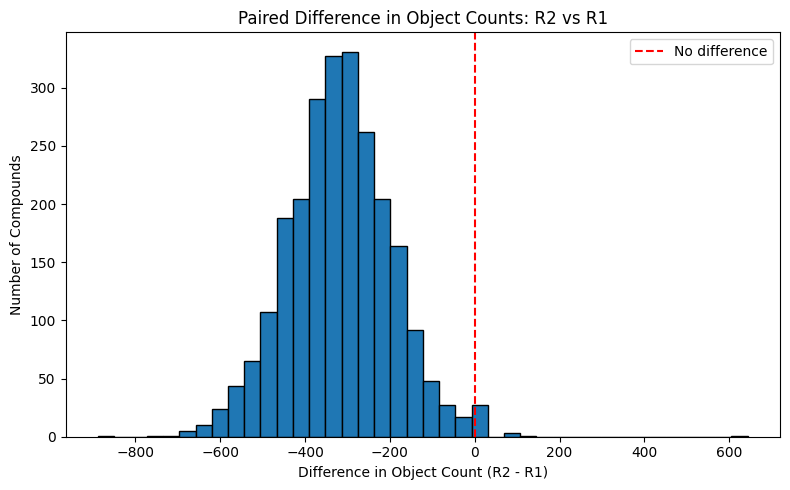

In [16]:
# Keep compounds with one observation in each batch
single_observation = compound_batch_counts[
    compound_batch_counts == 1
].index

df_single = df.set_index(
    ["Metadata_EOS", "Metadata_Batch"]
).loc[single_observation].reset_index()

# Compare R1 and R2 object counts for each compound
r1_r2 = df_single[
    df_single["Metadata_Batch"].isin(["R1", "R2"])
].pivot(
    index="Metadata_EOS",
    columns="Metadata_Batch",
    values="Metadata_Object_Count"
).dropna()

# Calculate differences
r1_r2["Difference"] = r1_r2["R2"] - r1_r2["R1"]

print("Compounds compared:", len(r1_r2))

print("Average difference (R2 - R1):",
      round(r1_r2["Difference"].mean(), 2))

print("Percentage with lower counts in R2:",
      round((r1_r2["Difference"] < 0).mean() * 100, 2), "%")
plt.figure(figsize=(8, 5))

plt.hist(
    r1_r2["Difference"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No difference"
)

plt.title("Paired Difference in Object Counts: R2 vs R1")
plt.xlabel("Difference in Object Count (R2 - R1)")
plt.ylabel("Number of Compounds")

plt.legend()
plt.tight_layout()
plt.show()

Compounds compared: 2444
R1 vs R2 nuclear area correlation: 0.846


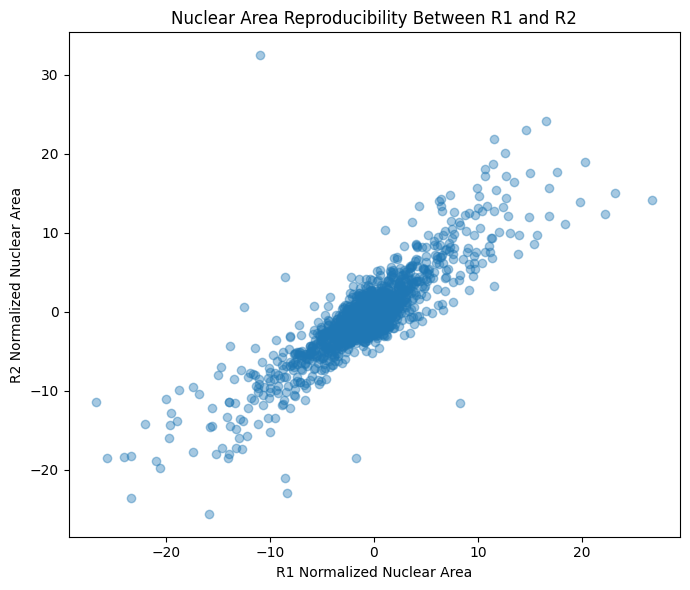

In [17]:
# Select nuclear area measurements from R1 and R2
nuclear_area = df_single[
    df_single["Metadata_Batch"].isin(["R1", "R2"])
].pivot(
    index="Metadata_EOS",
    columns="Metadata_Batch",
    values="Nuc_AreaShape_Area"
).dropna()

# Calculate correlation between R1 and R2
correlation = nuclear_area["R1"].corr(nuclear_area["R2"])

print("Compounds compared:", len(nuclear_area))
print("R1 vs R2 nuclear area correlation:", round(correlation, 3))

# Create scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    nuclear_area["R1"],
    nuclear_area["R2"],
    alpha=0.4
)

plt.xlabel("R1 Normalized Nuclear Area")
plt.ylabel("R2 Normalized Nuclear Area")
plt.title("Nuclear Area Reproducibility Between R1 and R2")

plt.tight_layout()
plt.show()

In [18]:
# Use the nonconstant morphological features
nonconstant_features = [
    col for col in feature_cols
    if col not in constant_features.index
]

# Separate R1 and R2 measurements
r1 = (
    df_single[df_single["Metadata_Batch"] == "R1"]
    .set_index("Metadata_EOS")
)

r2 = (
    df_single[df_single["Metadata_Batch"] == "R2"]
    .set_index("Metadata_EOS")
)

# Keep compounds present in both batches
common_compounds = r1.index.intersection(r2.index)

r1 = r1.loc[common_compounds]
r2 = r2.loc[common_compounds]

# Calculate correlation for each morphological feature
feature_correlations = r1[nonconstant_features].corrwith(
    r2[nonconstant_features]
)

print("Features evaluated:", feature_correlations.notna().sum())

print("\nCorrelation summary:")
display(feature_correlations.describe())

print("\nFive lowest correlations:")
display(feature_correlations.nsmallest(5))

print("\nFive highest correlations:")
display(feature_correlations.nlargest(5))

Features evaluated: 2887

Correlation summary:


,0
count,2887.000000
mean,0.590390
std,0.217113
min,-0.209280
25%,0.456603
50%,0.638325
75%,0.761208
max,0.931279



Five lowest correlations:


,0
Cyto_AreaShape_Zernike_3_3,-0.209280
Cells_AreaShape_Zernike_3_3,-0.179215
Cells_AreaShape_Zernike_9_1,-0.142850
Cyto_AreaShape_Zernike_9_9,-0.100543
Cells_AreaShape_Orientation,-0.100061



Five highest correlations:


,0
Cells_RadialDistribution_FracAtD_Mito_4of4,0.931279
Cells_RadialDistribution_MeanFrac_ER_4of4,0.926853
Cells_RadialDistribution_FracAtD_AGP_4of4,0.925234
Cells_Correlation_Manders_DNA_AGP,0.922165
Cells_Intensity_IntegratedIntensityEdge_AGP,0.916228


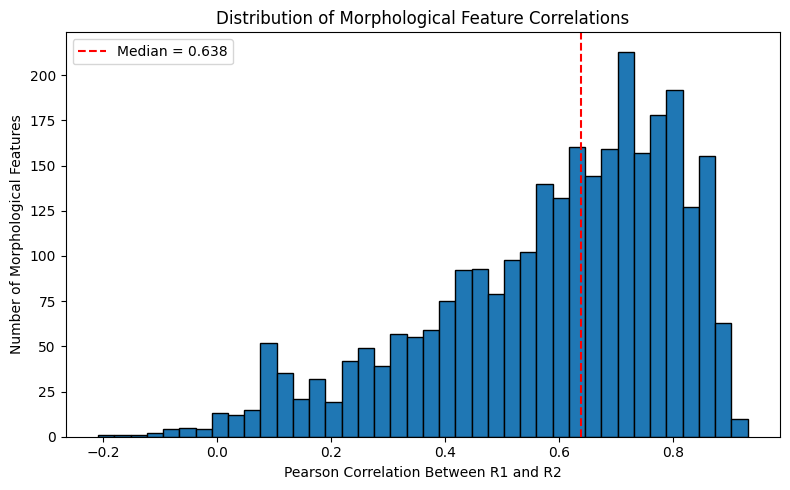

In [19]:
# Keep only valid correlation values
valid_correlations = feature_correlations.dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    valid_correlations,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    valid_correlations.median(),
    color="red",
    linestyle="--",
    label=f"Median = {valid_correlations.median():.3f}"
)

plt.title("Distribution of Morphological Feature Correlations")
plt.xlabel("Pearson Correlation Between R1 and R2")
plt.ylabel("Number of Morphological Features")

plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import numpy as np

# Keep features that vary in both R1 and R2
usable_features = [
    col for col in nonconstant_features
    if r1[col].nunique() > 1 and r2[col].nunique() > 1
]

# Calculate Euclidean distance between R1 and R2
differences = (
    r1[usable_features].to_numpy()
    - r2[usable_features].to_numpy()
)

distances = np.sqrt((differences ** 2).sum(axis=1))

# Store one disagreement score per compound
replicate_disagreement = pd.Series(
    distances,
    index=common_compounds,
    name="R1_R2_Disagreement"
)

print("Compounds evaluated:", len(replicate_disagreement))
print("Features used:", len(usable_features))

print("\nReplicate disagreement summary:")
display(replicate_disagreement.describe())

Compounds evaluated: 2444
Features used: 2887

Replicate disagreement summary:


,R1_R2_Disagreement
count,2.444000e+03
mean,3.279261e+19
std,5.294507e+20
min,5.564091e+01
25%,1.003865e+18
50%,1.414214e+18
75%,1.615465e+18
max,1.569409e+22


In [21]:
# Find the largest absolute value in each morphological feature
max_values = df[usable_features].abs().max()

# Display the 15 features with the largest values
print("Features with the largest absolute values:")
display(max_values.sort_values(ascending=False).head(15))

# Count features containing extremely large values
print("\nFeatures with values above 1 million:")
print((max_values > 1e6).sum())

Features with the largest absolute values:


,0
Nuc_ObjectSkeleton_NumberNonTrunkBranches_mito_skel,3.018600e+22
Nuc_ObjectSkeleton_NumberBranchEnds_mito_skel,1.385000e+21
Cyto_RadialDistribution_MeanFrac_mito_tubeness_14of20,5.800975e+18
Cyto_RadialDistribution_MeanFrac_mito_tubeness_11of16,5.796069e+18
Cells_Neighbors_NumberOfNeighbors_Adjacent,5.000000e+18
Nuc_ObjectSkeleton_NumberTrunks_mito_skel,5.000000e+18
Cyto_AreaShape_MaximumRadius,4.976147e+18
Nuc_AreaShape_MinFeretDiameter,4.890446e+18
Cells_RadialDistribution_MeanFrac_mito_tubeness_1of16,4.195260e+18
Cells_RadialDistribution_MeanFrac_mito_tubeness_1of20,4.195260e+18



Features with values above 1 million:
71


In [22]:
# Identify features with extremely large values
extreme_features = df[usable_features].abs().max() > 1e6

print("Features containing extreme values:",
      extreme_features.sum())

print("Features without extreme values:",
      (~extreme_features).sum())

Features containing extreme values: 71
Features without extreme values: 2816


In [23]:
# Select features without extreme values
safe_features = extreme_features.index[~extreme_features].tolist()

# Get matching R1 and R2 profiles
X_r1 = r1.loc[common_compounds, safe_features]
X_r2 = r2.loc[common_compounds, safe_features]

# Calculate standard deviation for each feature
combined = pd.concat([X_r1, X_r2])
feature_std = combined.std()

# Remove features with zero standard deviation
valid_features = feature_std[feature_std > 0].index

# Standardize the differences
differences = (
    X_r1[valid_features] - X_r2[valid_features]
) / feature_std[valid_features]

# Calculate Euclidean distance
distances = np.sqrt((differences ** 2).sum(axis=1))

# Display summary
print("Compounds evaluated:", len(distances))
print("Features used:", len(valid_features))

display(distances.describe())

Compounds evaluated: 2444
Features used: 2816


,0
count,2444.000000
mean,42.016899
std,28.156983
min,16.651684
25%,29.398725
50%,35.859628
75%,45.644552
max,476.365956


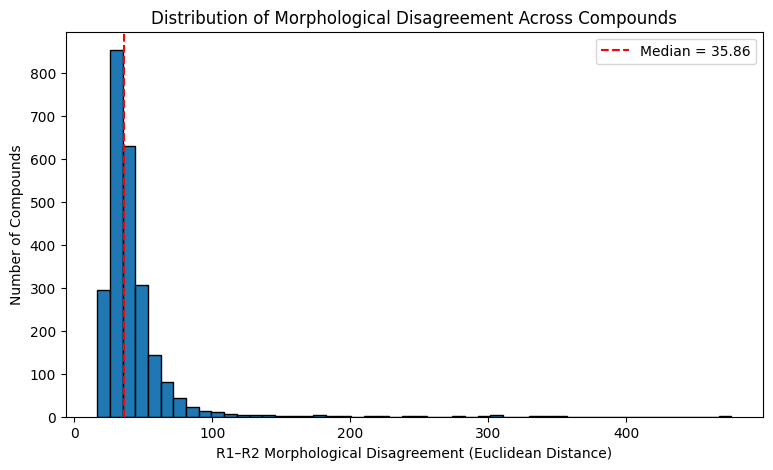

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(distances, bins=50, edgecolor="black")

plt.axvline(
    distances.median(),
    color="red",
    linestyle="--",
    label=f"Median = {distances.median():.2f}"
)

plt.xlabel("R1–R2 Morphological Disagreement (Euclidean Distance)")
plt.ylabel("Number of Compounds")
plt.title("Distribution of Morphological Disagreement Across Compounds")

plt.legend()
plt.show()

In [25]:
# Identify the 10 compounds with the highest disagreement
top_disagreement = distances.sort_values(ascending=False).head(10)

print("Top 10 compounds with highest R1–R2 disagreement:")
display(top_disagreement)

Top 10 compounds with highest R1–R2 disagreement:


,0
Metadata_EOS,
EOS101405,476.365956
EOS100060,351.924900
EOS100844,344.901338
EOS101315,330.696366
EOS101578,329.341980
EOS101406,307.620517
EOS100929,306.406123
EOS100966,305.220095
EOS100439,298.672948


In [26]:
# Get the 10 compounds with highest disagreement
top_compounds = top_disagreement.index

# Extract R1 and R2 object counts
object_counts = pd.DataFrame({
    "R1_Object_Count": r1.loc[top_compounds, "Metadata_Object_Count"],
    "R2_Object_Count": r2.loc[top_compounds, "Metadata_Object_Count"],
    "Morphological_Disagreement": top_disagreement
})

# Calculate the difference in object counts
object_counts["Object_Count_Difference"] = (
    object_counts["R2_Object_Count"]
    - object_counts["R1_Object_Count"]
)

display(object_counts)

,R1_Object_Count,R2_Object_Count,Morphological_Disagreement,Object_Count_Difference
Metadata_EOS,,,,
EOS101405,5,1,476.365956,-4
EOS100060,1,10,351.924900,9
EOS100844,1,4,344.901338,3
EOS101315,4,1,330.696366,-3
EOS101578,2,1,329.341980,-1
EOS101406,4,647,307.620517,643
EOS100929,3,2,306.406123,-1
EOS100966,28,1,305.220095,-27
EOS100439,1,4,298.672948,3


Text(0.5, 1.0, 'Relationship Between Object Count and Morphological Disagreement')

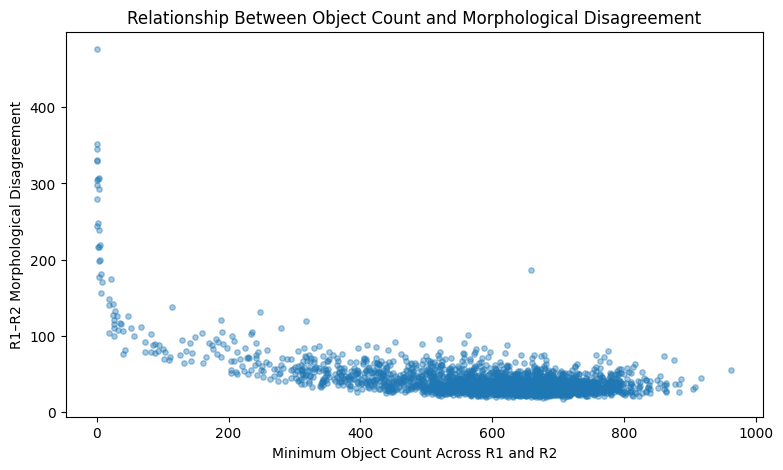

In [27]:
# Calculate minimum object count across R1 and R2
min_object_count = pd.concat([
    r1.loc[distances.index, "Metadata_Object_Count"],
    r2.loc[distances.index, "Metadata_Object_Count"]
], axis=1).min(axis=1)

# Create scatter plot
plt.figure(figsize=(9, 5))

plt.scatter(
    min_object_count,
    distances,
    alpha=0.4,
    s=15
)

plt.xlabel("Minimum Object Count Across R1 and R2")
plt.ylabel("R1–R2 Morphological Disagreement")
plt.title("Relationship Between Object Count and Morphological Disagreement")


In [28]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    min_object_count,
    distances
)

print("Spearman correlation:", round(correlation, 3))
print("P-value:", p_value)

Spearman correlation: -0.399
P-value: 4.5108329715010087e-94


In [29]:
# Count observations for each compound in each batch
batch_counts = df.groupby(
    ["Metadata_EOS", "Metadata_Batch"]
).size().unstack(fill_value=0)

# Keep compounds with exactly one observation in R1, R2, R3, and R4
eligible_compounds = batch_counts[
    (batch_counts[["R1", "R2", "R3", "R4"]] == 1).all(axis=1)
].index

print("Total unique compounds:", df["Metadata_EOS"].nunique())
print("Compounds eligible for analysis:", len(eligible_compounds))
print("Compounds excluded from initial analysis:",
      df["Metadata_EOS"].nunique() - len(eligible_compounds))

Total unique compounds: 2462
Compounds eligible for analysis: 2437
Compounds excluded from initial analysis: 25


In [30]:
# Keep only eligible compounds
df_prepared = df[
    df["Metadata_EOS"].isin(eligible_compounds)
].copy()

# Sort by compound and batch
df_prepared = df_prepared.sort_values(
    ["Metadata_EOS", "Metadata_Batch"]
).reset_index(drop=True)

# Check the prepared dataset
print("Prepared dataset shape:", df_prepared.shape)

print("Unique compounds:",
      df_prepared["Metadata_EOS"].nunique())

print("\nObservations per batch:")
print(df_prepared["Metadata_Batch"].value_counts().sort_index())

Prepared dataset shape: (9748, 2984)
Unique compounds: 2437

Observations per batch:
Metadata_Batch
R1    2437
R2    2437
R3    2437
R4    2437
Name: count, dtype: int64


In [31]:
# Create a table with R1 and R2 object counts for each compound
object_count_table = df_prepared.pivot(
    index="Metadata_EOS",
    columns="Metadata_Batch",
    values="Metadata_Object_Count"
)

# Create our feature engineering table
df_features = pd.DataFrame(index=object_count_table.index)

# Calculate predictors using only R1 and R2
df_features["Mean_Object_Count"] = (
    object_count_table["R1"] + object_count_table["R2"]
) / 2

df_features["Min_Object_Count"] = object_count_table[
    ["R1", "R2"]
].min(axis=1)

df_features["Object_Count_Difference"] = (
    object_count_table["R1"] - object_count_table["R2"]
).abs()

print("Feature table shape:", df_features.shape)

display(df_features.head())

Feature table shape: (2437, 3)


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference
Metadata_EOS,,,
EOS100001,515.0,330,370
EOS100002,806.0,608,396
EOS100003,405.5,295,221
EOS100004,653.5,515,277
EOS100005,786.5,716,141


In [32]:
# Add R1–R2 morphological disagreement
df_features["Morphological_Disagreement"] = distances.reindex(
    df_features.index
)

# Check our updated feature table
print("Feature table shape:", df_features.shape)

print("Missing values:")
print(df_features.isna().sum())

display(df_features.head())

Feature table shape: (2437, 4)
Missing values:
Mean_Object_Count             0
Min_Object_Count              0
Object_Count_Difference       0
Morphological_Disagreement    0
dtype: int64


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference,Morphological_Disagreement
Metadata_EOS,,,,
EOS100001,515.0,330,370,65.245843
EOS100002,806.0,608,396,46.213907
EOS100003,405.5,295,221,54.737291
EOS100004,653.5,515,277,37.931020
EOS100005,786.5,716,141,51.458991


In [33]:
# Use the same exploratory morphological feature set
model_features = safe_features

# Create one morphological profile table for each batch
profiles = {}

for batch in ["R1", "R2", "R3", "R4"]:
    profiles[batch] = (
        df_prepared[
            df_prepared["Metadata_Batch"] == batch
        ]
        .set_index("Metadata_EOS")
        .loc[df_features.index, model_features]
    )

# Verify that the profiles have matching dimensions
for batch, profile in profiles.items():
    print(batch, profile.shape)

R1 (2437, 2816)
R2 (2437, 2816)
R3 (2437, 2816)
R4 (2437, 2816)


In [34]:
# Average the first two replicates
initial_profile = (
    profiles["R1"] + profiles["R2"]
) / 2

# Average the first three replicates
updated_profile = (
    profiles["R1"] + profiles["R2"] + profiles["R3"]
) / 3

# Use R4 as the reference
reference_profile = profiles["R4"]

# Check dimensions
print("Initial profile:", initial_profile.shape)
print("Updated profile:", updated_profile.shape)
print("Reference profile:", reference_profile.shape)

Initial profile: (2437, 2816)
Updated profile: (2437, 2816)
Reference profile: (2437, 2816)


In [35]:
# Examine the standard deviation of each morphological feature
# using only the initial R1 and R2 measurements

initial_measurements = pd.concat([
    profiles["R1"],
    profiles["R2"]
])

feature_scales = initial_measurements.std()

print("Feature scale summary:")
display(feature_scales.describe())

print("Features with zero standard deviation:",
      (feature_scales == 0).sum())

Feature scale summary:


,0
count,2816.000000
mean,4.309928
std,31.333052
min,1.025313
25%,2.736684
50%,3.227697
75%,4.113663
max,1663.012009


Features with zero standard deviation: 0


In [36]:
# Standardize each profile using R1 and R2 feature scales

initial_scaled = initial_profile / feature_scales

updated_scaled = updated_profile / feature_scales

reference_scaled = reference_profile / feature_scales

# Verify dimensions
print("Initial:", initial_scaled.shape)
print("Updated:", updated_scaled.shape)
print("Reference:", reference_scaled.shape)

# Check for missing values
print("Missing values:", initial_scaled.isna().sum().sum())

Initial: (2437, 2816)
Updated: (2437, 2816)
Reference: (2437, 2816)
Missing values: 0


In [37]:
# Distance between initial profile and R4
distance_initial = np.sqrt(
    ((initial_scaled - reference_scaled) ** 2).sum(axis=1)
)

# Distance between updated profile and R4
distance_updated = np.sqrt(
    ((updated_scaled - reference_scaled) ** 2).sum(axis=1)
)

# Calculate the improvement from adding R3
improvement = distance_initial - distance_updated

# Create a table to inspect our results
df_improvement = pd.DataFrame({
    "Distance_Initial": distance_initial,
    "Distance_Updated": distance_updated,
    "Improvement": improvement
})

print("Improvement table shape:", df_improvement.shape)

display(df_improvement.head())

Improvement table shape: (2437, 3)


,Distance_Initial,Distance_Updated,Improvement
Metadata_EOS,,,
EOS100001,166.954454,163.743896,3.210558
EOS100002,136.616044,140.428270,-3.812225
EOS100003,150.666529,148.842202,1.824327
EOS100004,149.454789,151.235672,-1.780883
EOS100005,140.672460,139.676781,0.995679


In [38]:
# Count compounds where R3 improved agreement with R4
improved = (df_improvement["Improvement"] > 0).sum()

# Count compounds where R3 worsened agreement with R4
worsened = (df_improvement["Improvement"] < 0).sum()

# Count compounds with no change
unchanged = (df_improvement["Improvement"] == 0).sum()

total = len(df_improvement)

print("Total compounds:", total)
print("Improved:", improved)
print("Worsened:", worsened)
print("Unchanged:", unchanged)

print("\nPercentage improved:", round(improved / total * 100, 2), "%")
print("Percentage worsened:", round(worsened / total * 100, 2), "%")

print("\nImprovement summary:")
display(df_improvement["Improvement"].describe())

Total compounds: 2437
Improved: 1441
Worsened: 996
Unchanged: 0

Percentage improved: 59.13 %
Percentage worsened: 40.87 %

Improvement summary:


,Improvement
count,2437.000000
mean,0.582507
std,3.499071
min,-11.757733
25%,-1.392948
50%,0.659751
75%,2.372240
max,49.152380


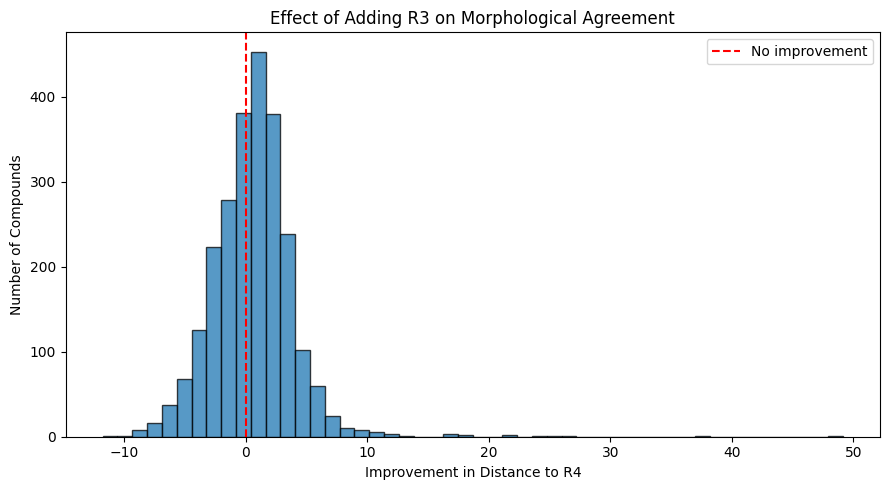

In [39]:
plt.figure(figsize=(9, 5))

plt.hist(
    df_improvement["Improvement"],
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="No improvement"
)

plt.xlabel("Improvement in Distance to R4")
plt.ylabel("Number of Compounds")
plt.title("Effect of Adding R3 on Morphological Agreement")
plt.legend()
plt.tight_layout()

In [42]:
# Combine our predictors with the improvement outcome
df_model = df_features.join(
    df_improvement[["Improvement"]]
)

# Create a binary outcome
# 1 = Adding R3 improved agreement with R4
# 0 = Adding R3 did not improve agreement

df_model["Improved"] = (
    df_model["Improvement"] > 0
).astype(int)

print("Machine learning dataset shape:", df_model.shape)

display(df_model.head())

print("\nTarget distribution:")
print(df_model["Improved"].value_counts())

Machine learning dataset shape: (2437, 6)


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference,Morphological_Disagreement,Improvement,Improved
Metadata_EOS,,,,,,
EOS100001,515.0,330,370,65.245843,3.210558,1
EOS100002,806.0,608,396,46.213907,-3.812225,0
EOS100003,405.5,295,221,54.737291,1.824327,1
EOS100004,653.5,515,277,37.931020,-1.780883,0
EOS100005,786.5,716,141,51.458991,0.995679,1



Target distribution:
Improved
1    1441
0     996
Name: count, dtype: int64
